# 04 - Visualisations

**Objectif** : Produire tous les graphiques du projet et les sauvegarder dans `figures/`.

Chaque graphique est accompagné d'un commentaire de lecture expliquant ce qu'on en déduit.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# Chemin du projet et des données
PROJECT_ROOT = Path(r'C:\Users\HP\Documents\education-employment-analysis')
CLEAN_DIR = PROJECT_ROOT / 'data' / 'clean'
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
FIGURES_DIR = PROJECT_ROOT / 'figures'

# Style global
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 130

# Palette et libellés cohérents pour tout le notebook
COLORS  = {'LOW': '#e07b54', 'MEDIUM': '#f0c05a', 'HIGH': '#4caf82'}
LABELS  = {'LOW': 'Faible (primaire)', 'MEDIUM': 'Intermédiaire (secondaire)', 'HIGH': 'Élevé (supérieur)'}
NIVEAUX = ['LOW', 'MEDIUM', 'HIGH']
BAR_COLORS  = [COLORS[k] for k in NIVEAUX]
X_LABELS    = [LABELS[k] for k in NIVEAUX]

# Chargement des données nettoyées
emploi  = pd.read_csv(CLEAN_DIR / 'emploi_clean.csv')
chomage = pd.read_csv(CLEAN_DIR / 'chomage_clean.csv')

# Fusion et calcul du taux de chômage
df = pd.merge(
    emploi [['country','year','education_level','nb_employes']],
    chomage[['country','year','education_level','nb_chomeurs']],
    on=['country','year','education_level'], how='inner'
)
df['taux_chomage'] = df['nb_chomeurs'] / (df['nb_employes'] + df['nb_chomeurs']) * 100

# Ajout de la région
REGIONS = {
    'FRA':'Europe','DEU':'Europe','ITA':'Europe','ESP':'Europe','GBR':'Europe',
    'POL':'Europe','NLD':'Europe','BEL':'Europe','SWE':'Europe','NOR':'Europe',
    'CHE':'Europe','AUT':'Europe','PRT':'Europe','GRC':'Europe','CZE':'Europe',
    'HUN':'Europe','ROU':'Europe','BGR':'Europe','HRV':'Europe','SVK':'Europe',
    'FIN':'Europe','DNK':'Europe','IRL':'Europe','LTU':'Europe','LVA':'Europe',
    'EST':'Europe','SVN':'Europe','RUS':'Europe','UKR':'Europe','SRB':'Europe',
    'ALB':'Europe','MDA':'Europe','MKD':'Europe','MNE':'Europe','BIH':'Europe',
    'ISL':'Europe','LUX':'Europe','MLT':'Europe','CYP':'Europe','BLR':'Europe',
    'USA':'Amériques','CAN':'Amériques','MEX':'Amériques','BRA':'Amériques',
    'ARG':'Amériques','COL':'Amériques','CHL':'Amériques','PER':'Amériques',
    'ECU':'Amériques','BOL':'Amériques','PRY':'Amériques','URY':'Amériques',
    'PAN':'Amériques','CRI':'Amériques','GTM':'Amériques','DOM':'Amériques',
    'VEN':'Amériques','SLV':'Amériques','HND':'Amériques','JAM':'Amériques',
    'CHN':'Asie-Pacifique','JPN':'Asie-Pacifique','KOR':'Asie-Pacifique',
    'IND':'Asie-Pacifique','IDN':'Asie-Pacifique','THA':'Asie-Pacifique',
    'VNM':'Asie-Pacifique','PHL':'Asie-Pacifique','MYS':'Asie-Pacifique',
    'AUS':'Asie-Pacifique','NZL':'Asie-Pacifique','SGP':'Asie-Pacifique',
    'BGD':'Asie-Pacifique','PAK':'Asie-Pacifique','LKA':'Asie-Pacifique',
    'KHM':'Asie-Pacifique','MNG':'Asie-Pacifique','NPL':'Asie-Pacifique',
    'ZAF':'Afrique','NGA':'Afrique','ETH':'Afrique','EGY':'Afrique',
    'DZA':'Afrique','MAR':'Afrique','TUN':'Afrique','GHA':'Afrique',
    'KEN':'Afrique','TZA':'Afrique','UGA':'Afrique','CMR':'Afrique',
    'CIV':'Afrique','SEN':'Afrique','ZMB':'Afrique','BWA':'Afrique',
    'SAU':'Moyen-Orient','IRN':'Moyen-Orient','TUR':'Moyen-Orient',
    'IRQ':'Moyen-Orient','ISR':'Moyen-Orient','JOR':'Moyen-Orient',
    'KWT':'Moyen-Orient','ARE':'Moyen-Orient','QAT':'Moyen-Orient',
    'LBN':'Moyen-Orient','OMN':'Moyen-Orient','PSE':'Moyen-Orient',
}
df['region'] = df['country'].map(REGIONS)

print('Données chargées et prêtes.')
print(f'Dataset : {len(df):,} lignes | {df["country"].nunique()} pays | {df["year"].min()}–{df["year"].max()}')

Données chargées et prêtes.
Dataset : 5,924 lignes | 175 pays | 2000–2023


---
## Figure 1 : Volume d'emploi et de chômage par niveau

**Question** : En volume absolu, quelle est la part de chaque niveau dans l'emploi et le chômage mondiaux ?

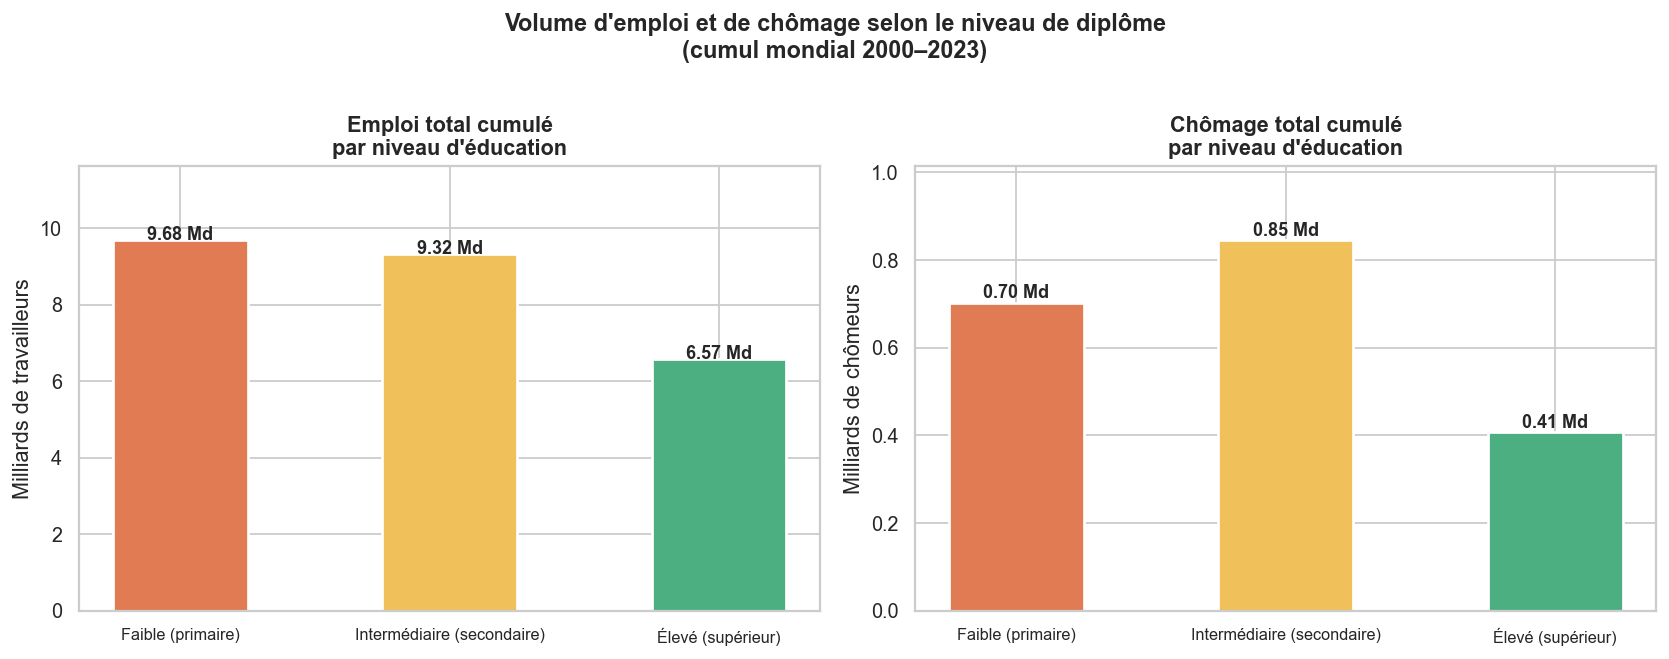


DESCRIPTION :
Les deux graphiques montrent le volume cumulé d'emploi (à gauche) et de chômage (à droite)
pour chaque niveau d'éducation sur la période 2000–2023.

CE QU'ON EN DÉDUIT :
En volume absolu, les peu diplômés (LOW) dominent aussi bien l'emploi que le chômage.
Cela reflète leur plus grand poids démographique, pas nécessairement une meilleure
insertion. Pour évaluer la protection réelle, il faut regarder les TAUX (graphique 2).


In [3]:
emp_global = df.groupby('education_level')['nb_employes'].sum().reindex(NIVEAUX)
une_global = df.groupby('education_level')['nb_chomeurs'].sum().reindex(NIVEAUX)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, titre, ylabel in zip(
    axes,
    [emp_global, une_global],
    ['Emploi total cumulé', 'Chômage total cumulé'],
    ['Milliards de travailleurs', 'Milliards de chômeurs']
):
    bars = ax.bar(X_LABELS, data.values / 1e6, color=BAR_COLORS,
                  edgecolor='white', linewidth=1.5, width=0.5)
    for b, v in zip(bars, data.values / 1e6):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{v:.2f} Md', ha='center', fontweight='bold', fontsize=10)
    ax.set_title(f'{titre}\npar niveau d\'éducation', fontweight='bold', fontsize=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, data.max() / 1e6 * 1.2)
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle('Volume d\'emploi et de chômage selon le niveau de diplôme\n(cumul mondial 2000–2023)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_vue_globale.png', bbox_inches='tight')
plt.show()

print()
print('DESCRIPTION :')
print('Les deux graphiques montrent le volume cumulé d\'emploi (à gauche) et de chômage (à droite)')
print('pour chaque niveau d\'éducation sur la période 2000–2023.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('En volume absolu, les peu diplômés (LOW) dominent aussi bien l\'emploi que le chômage.')
print('Cela reflète leur plus grand poids démographique, pas nécessairement une meilleure')
print('insertion. Pour évaluer la protection réelle, il faut regarder les TAUX (graphique 2).')

---
## Figure 2 : Taux de chômage moyen par niveau

**Question** : Tous les diplômes protègent-ils du chômage de la même manière ? (SQ3)

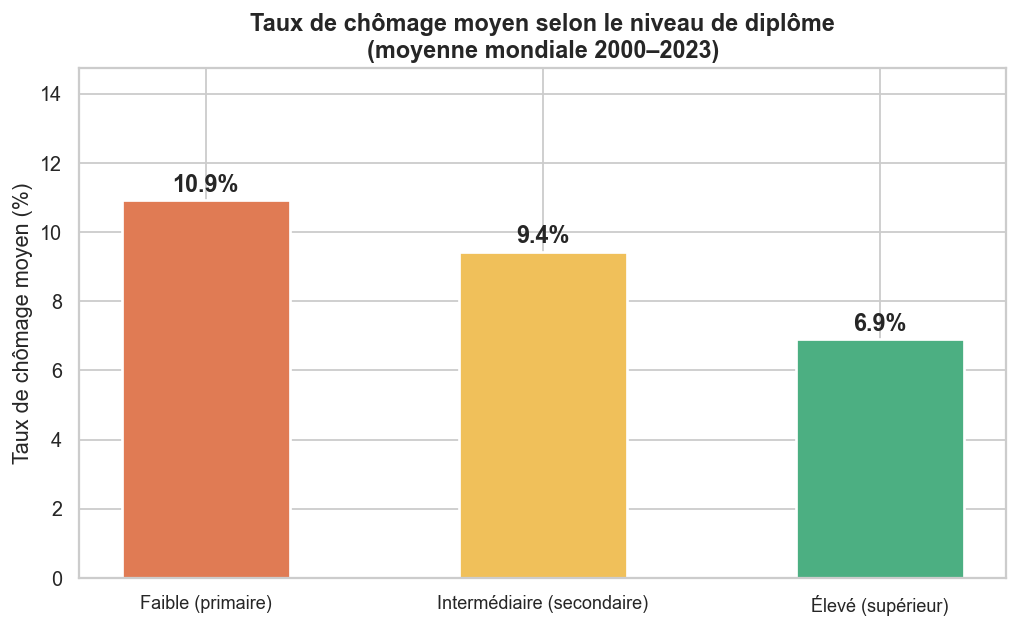


DESCRIPTION :
Ce graphique montre le taux de chômage moyen mondial pour chaque niveau d'éducation.
LOW = 10.9%, MEDIUM = 9.4%, HIGH = 6.9%.

CE QU'ON EN DÉDUIT :
Le taux de chômage diminue à chaque niveau de diplôme supplémentaire.
L'écart entre peu et très diplômés est de 4.0 points de pourcentage.
Le diplôme constitue un facteur de protection clair et mesurable contre le chômage.


In [4]:
taux_par_niveau = df.groupby('education_level')['taux_chomage'].mean().reindex(NIVEAUX)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(X_LABELS, taux_par_niveau.values, color=BAR_COLORS,
              edgecolor='white', linewidth=1.5, width=0.5)
for b, v in zip(bars, taux_par_niveau.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.1,
            f'{v:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=13)

ax.set_title('Taux de chômage moyen selon le niveau de diplôme\n(moyenne mondiale 2000–2023)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Taux de chômage moyen (%)')
ax.set_ylim(0, taux_par_niveau.max() * 1.35)
ax.tick_params(axis='x', labelsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_taux_chomage_niveaux.png', bbox_inches='tight')
plt.show()

ecart = taux_par_niveau['LOW'] - taux_par_niveau['HIGH']
print()
print('DESCRIPTION :')
print('Ce graphique montre le taux de chômage moyen mondial pour chaque niveau d\'éducation.')
print(f'LOW = {taux_par_niveau["LOW"]:.1f}%, MEDIUM = {taux_par_niveau["MEDIUM"]:.1f}%, HIGH = {taux_par_niveau["HIGH"]:.1f}%.')
print()
print('CE QU\'ON EN DÉDUIT :')
print(f'Le taux de chômage diminue à chaque niveau de diplôme supplémentaire.')
print(f'L\'écart entre peu et très diplômés est de {ecart:.1f} points de pourcentage.')
print('Le diplôme constitue un facteur de protection clair et mesurable contre le chômage.')

---
## Figure 3 : Évolution temporelle du taux de chômage

**Question** : La protection du diplôme est-elle stable dans le temps, y compris lors des crises ?

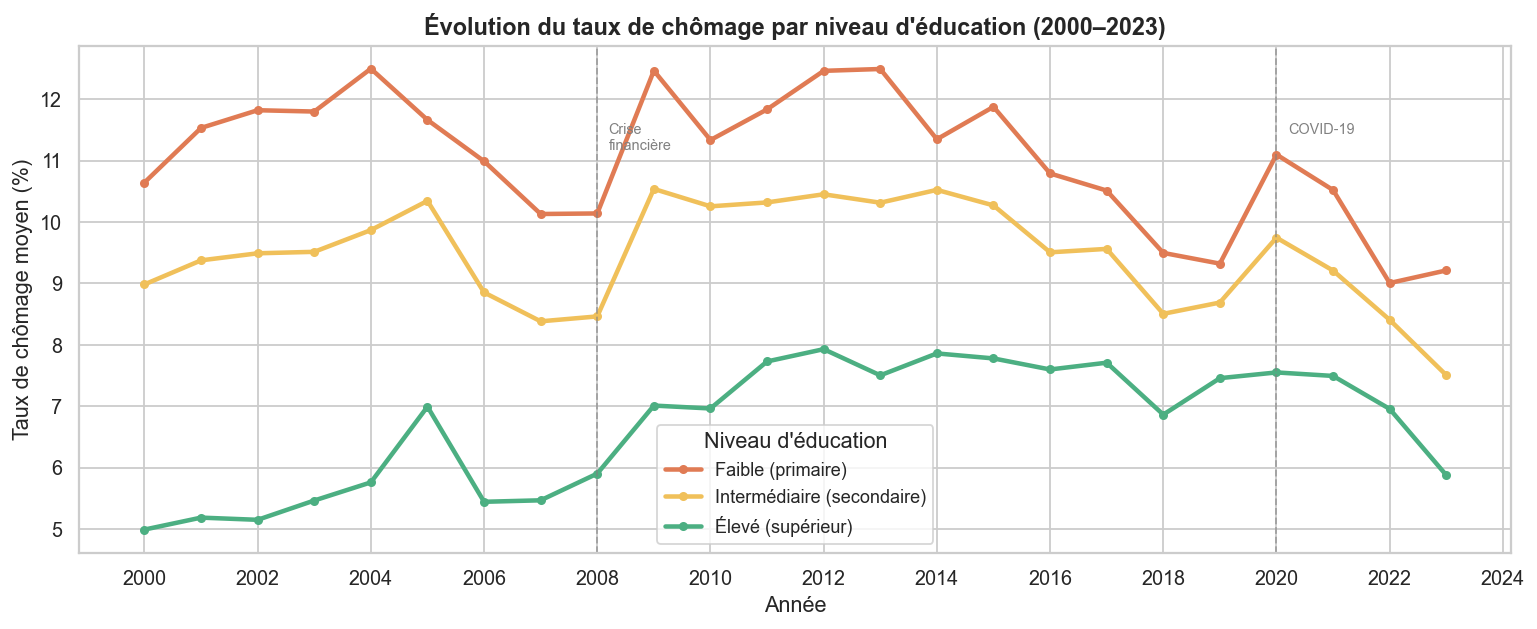


DESCRIPTION :
Ce graphique montre l'évolution du taux de chômage moyen mondial de 2000 à 2023,
pour chaque niveau d'éducation. Les lignes grises indiquent la crise de 2008 et la pandémie.

CE QU'ON EN DÉDUIT :
Les trois courbes montent lors des chocs économiques (2008, 2020), ce qui montre que
toutes les catégories sont affectées. Cependant, la courbe HIGH (vert) reste constamment
en dessous : le diplôme protège à tout moment, crises comprises.


In [5]:
taux_time = df.groupby(['year','education_level'])['taux_chomage'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))

for niv in NIVEAUX:
    sub = taux_time[taux_time['education_level'] == niv]
    ax.plot(sub['year'], sub['taux_chomage'],
            label=LABELS[niv], color=COLORS[niv],
            linewidth=2.5, marker='o', markersize=4)

# Repères événements
for annee, texte in [(2008, 'Crise\nfinancière'), (2020, 'COVID-19')]:
    ax.axvline(annee, color='grey', linestyle='--', linewidth=1, alpha=0.6)
    ax.text(annee + 0.2, taux_time['taux_chomage'].max() * 0.93,
            texte, fontsize=8, color='grey', va='top')

ax.set_title('Évolution du taux de chômage par niveau d\'éducation (2000–2023)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Année')
ax.set_ylabel('Taux de chômage moyen (%)')
ax.legend(title='Niveau d\'éducation', fontsize=10)
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_evolution_temporelle.png', bbox_inches='tight')
plt.show()

print()
print('DESCRIPTION :')
print('Ce graphique montre l\'évolution du taux de chômage moyen mondial de 2000 à 2023,')
print('pour chaque niveau d\'éducation. Les lignes grises indiquent la crise de 2008 et la pandémie.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('Les trois courbes montent lors des chocs économiques (2008, 2020), ce qui montre que')
print('toutes les catégories sont affectées. Cependant, la courbe HIGH (vert) reste constamment')
print('en dessous : le diplôme protège à tout moment, crises comprises.')

---
## Figure 4 — Comparaison par région du monde

**Question** : Le diplôme protège-t-il de la même façon selon la région ? (SQ1)

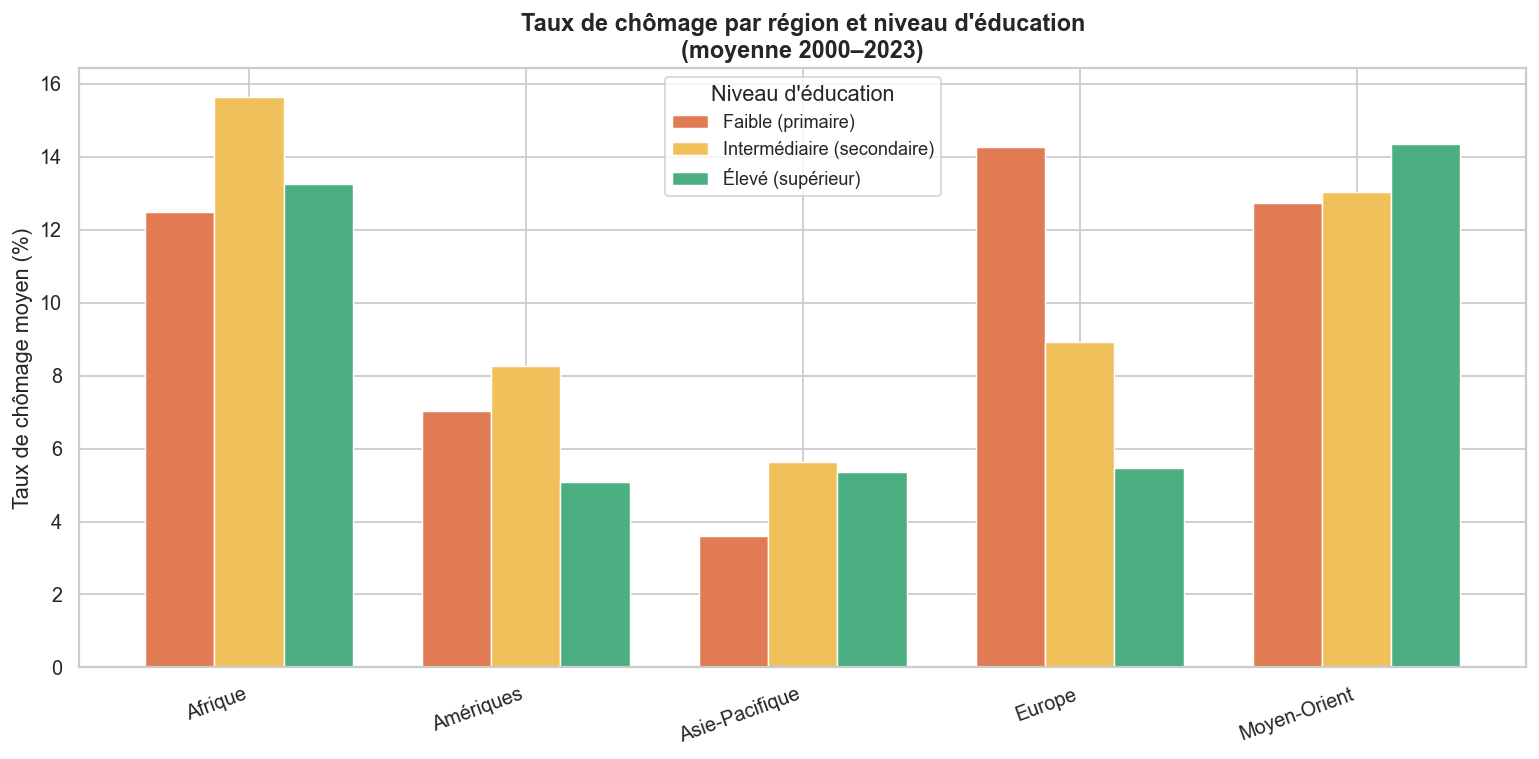


DESCRIPTION :
Ce graphique compare, pour chaque région du monde, le taux de chômage moyen
selon les trois niveaux d'éducation.

CE QU'ON EN DÉDUIT :
Dans toutes les régions, le taux diminue de LOW (rouge) à HIGH (vert).
Mais l'intensité de cette protection varie :
  Europe         : écart LOW–HIGH = 8.8 pts
  Amériques      : écart LOW–HIGH = 1.9 pts
  Afrique        : écart LOW–HIGH = -0.8 pts
  Moyen-Orient   : écart LOW–HIGH = -1.6 pts
  Asie-Pacifique : écart LOW–HIGH = -1.8 pts
→ Le diplôme ne protège pas avec la même intensité selon la région.


In [6]:
df_region = df[df['region'].notna()].copy()
taux_region = (
    df_region.groupby(['region','education_level'])['taux_chomage']
    .mean().reset_index()
)
pivot = taux_region.pivot(index='region', columns='education_level', values='taux_chomage')[NIVEAUX]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(pivot))
w = 0.25

for i, niv in enumerate(NIVEAUX):
    ax.bar(x + i*w, pivot[niv], w, label=LABELS[niv],
           color=COLORS[niv], edgecolor='white', linewidth=0.8)

ax.set_xticks(x + w)
ax.set_xticklabels(pivot.index, rotation=20, ha='right', fontsize=11)
ax.set_title('Taux de chômage par région et niveau d\'éducation\n(moyenne 2000–2023)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Taux de chômage moyen (%)')
ax.legend(title='Niveau d\'éducation', fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_chomage_par_region.png', bbox_inches='tight')
plt.show()

ecarts = (pivot['LOW'] - pivot['HIGH']).sort_values(ascending=False)
print()
print('DESCRIPTION :')
print('Ce graphique compare, pour chaque région du monde, le taux de chômage moyen')
print('selon les trois niveaux d\'éducation.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('Dans toutes les régions, le taux diminue de LOW (rouge) à HIGH (vert).')
print('Mais l\'intensité de cette protection varie :')
for region, ecart in ecarts.items():
    print(f'  {region:15s}: écart LOW–HIGH = {ecart:.1f} pts')
print('→ Le diplôme ne protège pas avec la même intensité selon la région.')

---
## Figure 5 : Zoom sur les diplômes universitaires

**Question** : Les diplômes universitaires ont-ils tous la même valeur sur le marché du travail ? (SQ2)

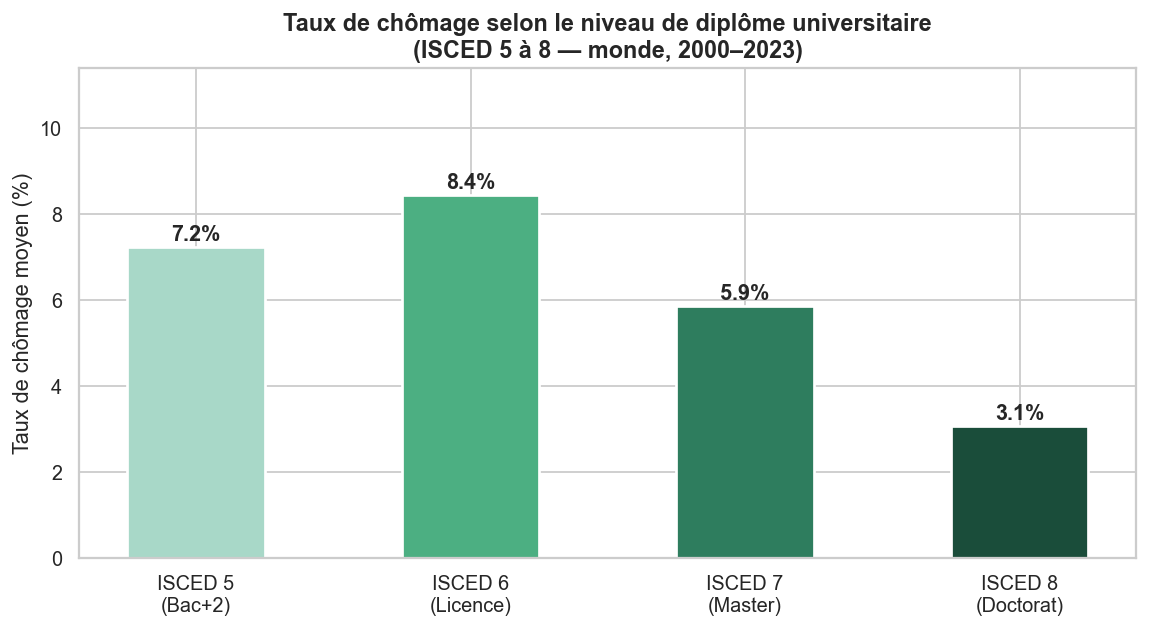


DESCRIPTION :
Ce graphique compare le taux de chômage pour chaque niveau de diplôme universitaire :
  ISCED 5 = Bac+2 (BTS, DUT...) | ISCED 6 = Licence | ISCED 7 = Master | ISCED 8 = Doctorat

CE QU'ON EN DÉDUIT :
  Bac+2    : 7.2%  — moins protégé dans le supérieur
  Doctorat : 3.1%  — le mieux protégé
  Écart    : 4.2 pts
Les diplômes universitaires ne sont pas équivalents : plus le diplôme est élevé,
plus la protection contre le chômage est forte.


In [7]:
# Rechargement des bruts pour les codes ISCED détaillés
emp_raw = pd.read_csv(RAW_DIR / 'EMP_TEMP_SEX_EDU_NB_A.csv')
une_raw = pd.read_csv(RAW_DIR / 'UNE_TUNE_SEX_EDU_NB_A.csv')

ISCED_SUP = ['EDU_ISCED11_5', 'EDU_ISCED11_6', 'EDU_ISCED11_7', 'EDU_ISCED11_8']
ISCED_LABELS = {
    'EDU_ISCED11_5': 'ISCED 5\n(Bac+2)',
    'EDU_ISCED11_6': 'ISCED 6\n(Licence)',
    'EDU_ISCED11_7': 'ISCED 7\n(Master)',
    'EDU_ISCED11_8': 'ISCED 8\n(Doctorat)',
}

def filtrer_sup(df_raw, col):
    return df_raw[
        (df_raw['sex'] == 'SEX_T') &
        (df_raw['classif1'].isin(ISCED_SUP)) &
        (df_raw['obs_value'].notna()) &
        (df_raw['obs_status'] != 'U') &
        (df_raw['time'] >= 2000) & (df_raw['time'] <= 2023)
    ][['ref_area','time','classif1','obs_value']].rename(
        columns={'ref_area':'country','time':'year','classif1':'education_code','obs_value': col})

df_sup = pd.merge(filtrer_sup(emp_raw,'nb_employes'), filtrer_sup(une_raw,'nb_chomeurs'),
                  on=['country','year','education_code'], how='inner')
df_sup['taux'] = df_sup['nb_chomeurs'] / (df_sup['nb_chomeurs'] + df_sup['nb_employes']) * 100

taux_sup = df_sup.groupby('education_code')['taux'].mean().reindex(ISCED_SUP)

# Graphique
couleurs_sup = ['#a8d8c8', '#4caf82', '#2e7d5e', '#1a4d3a']
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar([ISCED_LABELS[c] for c in ISCED_SUP], taux_sup.values,
              color=couleurs_sup, edgecolor='white', linewidth=1.5, width=0.5)
for b, v in zip(bars, taux_sup.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.05,
            f'{v:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_title('Taux de chômage selon le niveau de diplôme universitaire\n(ISCED 5 à 8 — monde, 2000–2023)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Taux de chômage moyen (%)')
ax.set_ylim(0, taux_sup.max() * 1.35)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_niveaux_universitaires.png', bbox_inches='tight')
plt.show()

print()
print('DESCRIPTION :')
print('Ce graphique compare le taux de chômage pour chaque niveau de diplôme universitaire :')
print('  ISCED 5 = Bac+2 (BTS, DUT...) | ISCED 6 = Licence | ISCED 7 = Master | ISCED 8 = Doctorat')
print()
print('CE QU\'ON EN DÉDUIT :')
print(f'  Bac+2    : {taux_sup["EDU_ISCED11_5"]:.1f}%  — moins protégé dans le supérieur')
print(f'  Doctorat : {taux_sup["EDU_ISCED11_8"]:.1f}%  — le mieux protégé')
print(f'  Écart    : {taux_sup["EDU_ISCED11_5"] - taux_sup["EDU_ISCED11_8"]:.1f} pts')
print('Les diplômes universitaires ne sont pas équivalents : plus le diplôme est élevé,')
print('plus la protection contre le chômage est forte.')

---
## Figure 06 — Le diplôme réduit les inégalités de genre… mais ne les efface pas

In [11]:
# Load raw data and compute gender-specific unemployment rates
emp_raw = pd.read_csv(RAW_DIR / 'EMP_TEMP_SEX_EDU_NB_A.csv')
une_raw = pd.read_csv(RAW_DIR / 'UNE_TUNE_SEX_EDU_NB_A.csv')

CODES_NIVEAU = {'EDU_AGGREGATE_BAS': 'LOW', 'EDU_AGGREGATE_INT': 'MEDIUM', 'EDU_AGGREGATE_ADV': 'HIGH'}
CODES = ['EDU_AGGREGATE_BAS', 'EDU_AGGREGATE_INT', 'EDU_AGGREGATE_ADV']

def build_by_gender(sex_filter):
    """Build employment + unemployment dataset filtered by gender (SEX_T, SEX_F, or SEX_M)"""
    e = emp_raw[
        (emp_raw['sex'] == sex_filter) & (emp_raw['classif1'].isin(CODES)) &
        emp_raw['obs_value'].notna() & (emp_raw['obs_status'] != 'U') &
        (emp_raw['time'] >= 2000) & (emp_raw['time'] <= 2023)
    ]
    u = une_raw[
        (une_raw['sex'] == sex_filter) & (une_raw['classif1'].isin(CODES)) &
        une_raw['obs_value'].notna() & (une_raw['obs_status'] != 'U') &
        (une_raw['time'] >= 2000) & (une_raw['time'] <= 2023)
    ]
    df_merged = pd.merge(
        e[['ref_area','time','classif1','obs_value']].rename(columns={'obs_value':'emp'}),
        u[['ref_area','time','classif1','obs_value']].rename(columns={'obs_value':'une'}),
        on=['ref_area','time','classif1'], how='inner'
    )
    df_merged['taux'] = df_merged['une'] / (df_merged['une'] + df_merged['emp']) * 100
    df_merged['niveau'] = df_merged['classif1'].map(CODES_NIVEAU)
    return df_merged

df_f = build_by_gender('SEX_F')
df_m = build_by_gender('SEX_M')

# Compute average rates by education level and gender
taux_f = df_f.groupby('niveau')['taux'].mean().reindex(['LOW', 'MEDIUM', 'HIGH'])
taux_m = df_m.groupby('niveau')['taux'].mean().reindex(['LOW', 'MEDIUM', 'HIGH'])

print('Gender data loaded and computed.')
print(f'Women: {df_f["ref_area"].nunique()} countries | Men: {df_m["ref_area"].nunique()} countries')

Gender data loaded and computed.
Women: 174 countries | Men: 174 countries


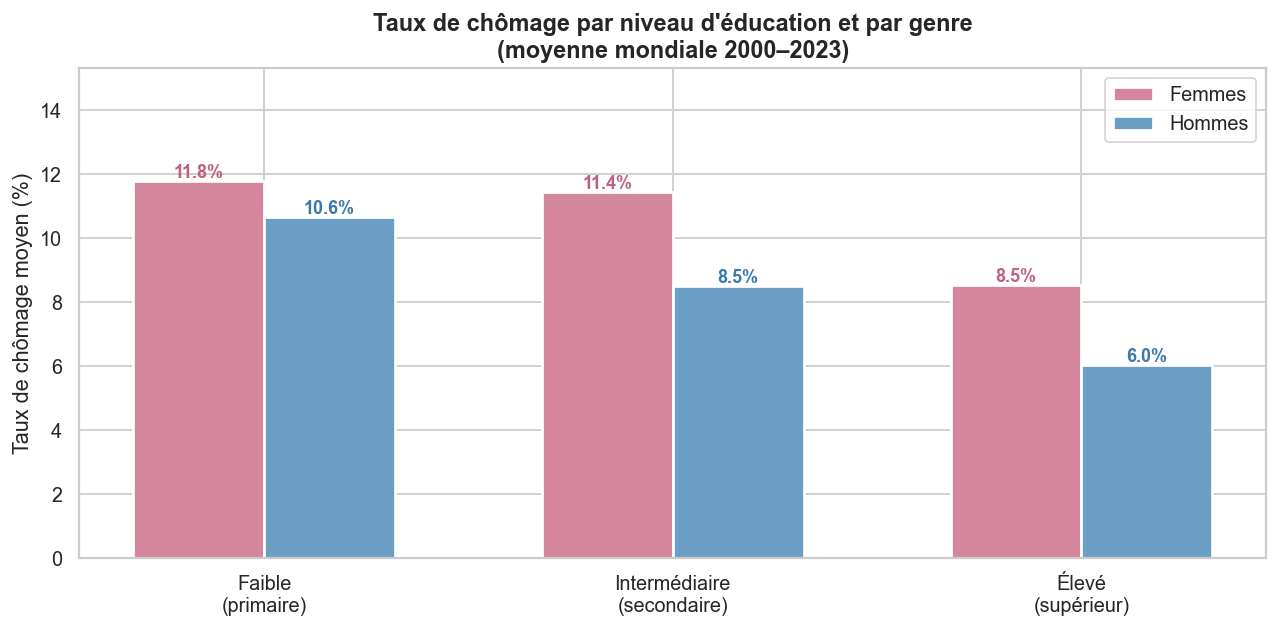

DESCRIPTION :
Taux de chômage moyen mondial pour les femmes et les hommes, par niveau de diplôme.

CE QU'ON EN DÉDUIT :
  Écart F–H niveau LOW  : +1.1 pts en défaveur des femmes
  Écart F–H niveau HIGH : +2.5 pts en défaveur des femmes
Le diplôme réduit l'écart de genre mais ne l'efface pas — même très diplômées,
les femmes restent désavantagées sur le marché du travail.


In [12]:
x        = np.arange(3)
w        = 0.32
x_labels = ['Faible\n(primaire)', 'Intermédiaire\n(secondaire)', 'Élevé\n(supérieur)']

fig, ax = plt.subplots(figsize=(10, 5))

bars_f = ax.bar(x - w/2, taux_f.values, w, label='Femmes',
                color='#d4869c', edgecolor='white', linewidth=1.5)
bars_m = ax.bar(x + w/2, taux_m.values, w, label='Hommes',
                color='#6a9ec5', edgecolor='white', linewidth=1.5)

for b, v in zip(bars_f, taux_f.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.1,
            f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold', color='#c06080')
for b, v in zip(bars_m, taux_m.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.1,
            f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold', color='#3a7aaa')

ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=11)
ax.set_ylabel('Taux de chômage moyen (%)')
ax.set_ylim(0, max(taux_f.max(), taux_m.max()) * 1.3)
ax.set_title('Taux de chômage par niveau d\'éducation et par genre\n(moyenne mondiale 2000–2023)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_genre_par_niveau.png', bbox_inches='tight')
plt.show()

ecart_low  = taux_f['LOW']  - taux_m['LOW']
ecart_high = taux_f['HIGH'] - taux_m['HIGH']
print('DESCRIPTION :')
print('Taux de chômage moyen mondial pour les femmes et les hommes, par niveau de diplôme.')
print()
print('CE QU\'ON EN DÉDUIT :')
print(f'  Écart F–H niveau LOW  : +{ecart_low:.1f} pts en défaveur des femmes')
print(f'  Écart F–H niveau HIGH : +{ecart_high:.1f} pts en défaveur des femmes')
print('Le diplôme réduit l\'écart de genre mais ne l\'efface pas — même très diplômées,')
print('les femmes restent désavantagées sur le marché du travail.')

---
## Figure 07 — Évolution temporelle des très diplômés par genre

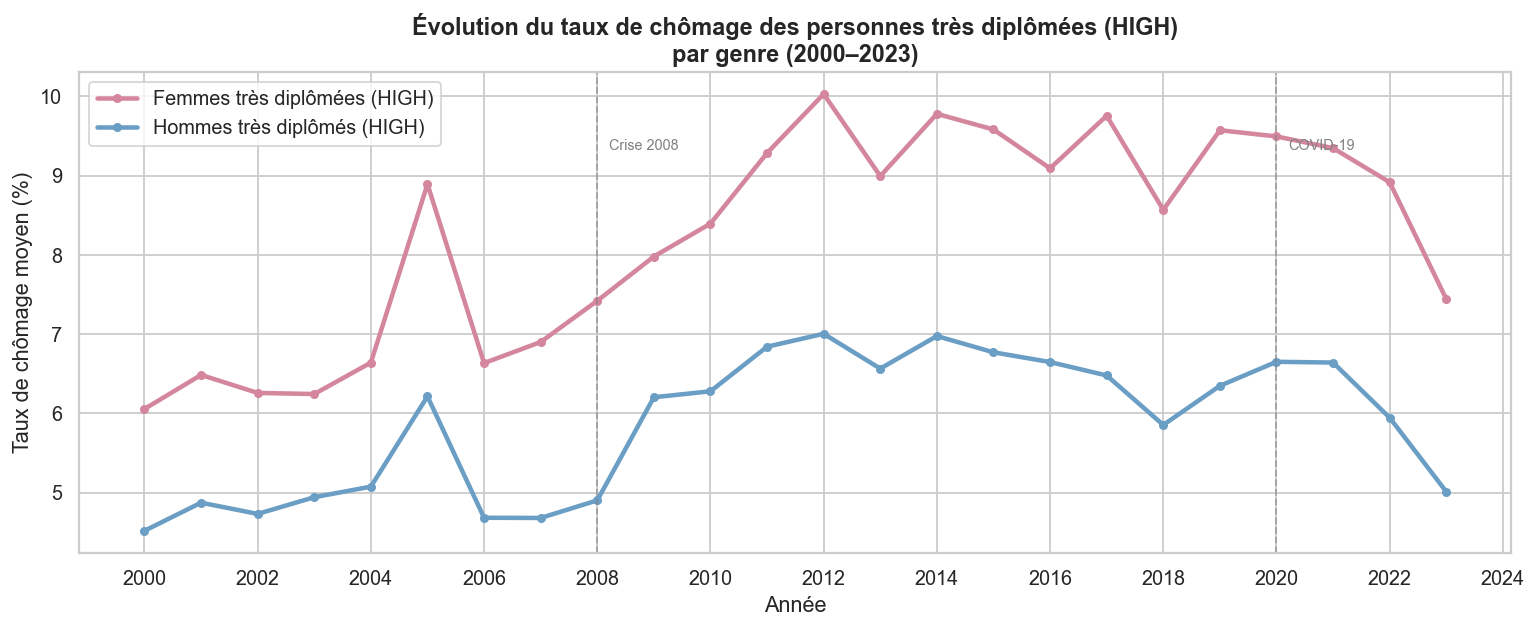

DESCRIPTION :
Évolution 2000–2023 du taux de chômage des très diplômés, femmes vs hommes.

CE QU'ON EN DÉDUIT :
L'écart persiste dans le temps mais tend à se réduire légèrement après 2010,
signe d'une amélioration progressive — mais lente — de l'égalité dans l'emploi qualifié.


In [14]:
t_f = df_f[df_f['niveau'] == 'HIGH'].groupby('time')['taux'].mean()
t_m = df_m[df_m['niveau'] == 'HIGH'].groupby('time')['taux'].mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(t_f.index, t_f.values, label='Femmes très diplômées (HIGH)',
        color='#d4869c', linewidth=2.5, marker='o', markersize=4)
ax.plot(t_m.index, t_m.values, label='Hommes très diplômés (HIGH)',
        color='#6a9ec5', linewidth=2.5, marker='o', markersize=4)

for annee, texte in [(2008, 'Crise 2008'), (2020, 'COVID-19')]:
    ax.axvline(annee, color='grey', linestyle='--', linewidth=1, alpha=0.6)
    ax.text(annee + 0.2, max(t_f.max(), t_m.max()) * 0.93,
            texte, fontsize=8, color='grey')

ax.set_title('Évolution du taux de chômage des personnes très diplômées (HIGH)\npar genre (2000–2023)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Année')
ax.set_ylabel('Taux de chômage moyen (%)')
ax.legend(fontsize=11)
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))

plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_genre_evolution.png', bbox_inches='tight')
plt.show()

print('DESCRIPTION :')
print('Évolution 2000–2023 du taux de chômage des très diplômés, femmes vs hommes.')
print()
print('CE QU\'ON EN DÉDUIT :')
print('L\'écart persiste dans le temps mais tend à se réduire légèrement après 2010,')
print('signe d\'une amélioration progressive — mais lente — de l\'égalité dans l\'emploi qualifié.')